# Phase I · Hypothesis 2: Word clusters and model behaviour

This notebook investigates **Hypothesis #2**: whether characteristic words or topics are associated with stronger or weaker irony predictions. It compares word-associated model probabilities with the true label distribution, then tests selected words through controlled edits.

**Reproduce the analysis:** Select your `Python (AiVis)` kernel and run **Kernel → Restart & Run All**. The TweetEval data and pretrained model are downloaded on first use. CSV files are written to the notebook's working directory.

**Scope:** The pretrained `cardiffnlp/twitter-roberta-base-irony` model detects irony, *not sentiment*. All results here are exploratory associations or black-box input modifications; they do not measure learned word embeddings.

## 1. Imports and GPU check

In [4]:
import re
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, silhouette_score
from transformers import pipeline

DEVICE = 0 if torch.cuda.is_available() else -1
print("CUDA available:", torch.cuda.is_available())
if DEVICE >= 0:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

W1110 19:45:28.179000 33404 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER


## 2. Load model and TweetEval irony test data

In [6]:
MODEL_NAME = "cardiffnlp/twitter-roberta-base-irony"
classifier = pipeline("text-classification", model=MODEL_NAME, device=DEVICE)


def predict_irony(texts, batch_size=32):
    """Return the model's P(irony) for each input text, in input order."""
    texts = list(texts)
    if not texts:
        return np.empty(0, dtype=float)
    outputs = classifier(texts, batch_size=batch_size, truncation=True, top_k=None)
    return np.asarray([
        next(item["score"] for item in pred if item["label"] == "irony")
        for pred in outputs
    ], dtype=float)


print("Model labels:", classifier.model.config.id2label)
print("P(irony) for 'Great':", predict_irony(["Great"])[0])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model labels: {0: 'non_irony', 1: 'irony'}
P(irony) for 'Great': 0.9368751049041748


In [7]:
BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/irony/"


def load_file(filename):
    with urllib.request.urlopen(BASE_URL + filename) as response:
        return response.read().decode("utf-8").splitlines()


texts = load_file("test_text.txt")
labels = [int(x) for x in load_file("test_labels.txt")]
assert len(texts) == len(labels), "Text and label files have different lengths"

df = pd.DataFrame({"text": texts, "irony": labels})
print("Tweets:", len(df))
print("True labels (0 = non-irony, 1 = irony):")
print(df["irony"].value_counts().sort_index())
display(df.head())

Tweets: 784
True labels (0 = non-irony, 1 = irony):
irony
0    473
1    311
Name: count, dtype: int64


,text,irony
0,@user Can U Help?||More conservatives needed o...,0
1,"Just walked in to #Starbucks and asked for a ""...",1
2,#NOT GONNA WIN,0
3,@user He is exactly that sort of person. Weirdo!,0
4,So much #sarcasm at work mate 10/10 #boring 10...,1


In [8]:
df["p_irony"] = predict_irony(df["text"])
df["p_non_irony"] = 1 - df["p_irony"]
df["prediction"] = (df["p_irony"] >= 0.5).astype(int)
df["correct"] = df["prediction"].eq(df["irony"])
df["confidence"] = df[["p_irony", "p_non_irony"]].max(axis=1)

display(df.head())

,text,irony,p_irony,p_non_irony,prediction,correct,confidence
0,@user Can U Help?||More conservatives needed o...,0,0.606072,0.393928,1,False,0.606072
1,"Just walked in to #Starbucks and asked for a ""...",1,0.956790,0.043210,1,True,0.956790
2,#NOT GONNA WIN,0,0.160630,0.839370,0,True,0.839370
3,@user He is exactly that sort of person. Weirdo!,0,0.915785,0.084215,1,False,0.915785
4,So much #sarcasm at work mate 10/10 #boring 10...,1,0.224913,0.775087,0,False,0.775087


## 3. Initial model behavior

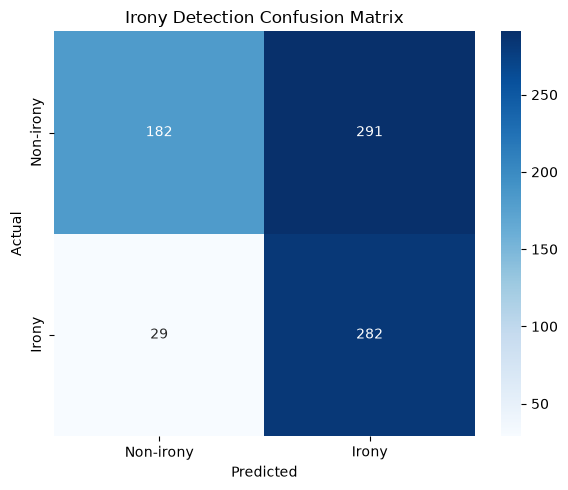

Accuracy: 59.2%


In [10]:
cm = confusion_matrix(df["irony"], df["prediction"], labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-irony", "Irony"],
    yticklabels=["Non-irony", "Irony"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Irony Detection Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"Accuracy: {df['correct'].mean():.1%}")
df.to_csv("irony_predictions.csv", sep=";", index=False, encoding="utf-8-sig")

In [47]:
errors = df.loc[~df["correct"], [
    "text", "irony", "prediction", "p_irony", "confidence"
]].sort_values("confidence", ascending=False)
print("Highest-confidence errors:")
display(errors.head(20))

Highest-confidence errors:


,text,irony,prediction,p_irony,confidence
635,"I'm officially making today ""Single men get a ...",0,1,0.992114,0.992114
427,Welcome to the surrealist estate agency!!,0,1,0.991513,0.991513
197,Nice touch. All the bar staff in the ground we...,0,1,0.991159,0.991159
5,Corny jokes are my absolute favorite,0,1,0.990908,0.990908
204,@user his daughter is painting his toes! That ...,0,1,0.987757,0.987757
700,Today was a very good day in Iceland.,0,1,0.986213,0.986213
71,Getting Final Jeopardy correct on Kids Jeopard...,0,1,0.986187,0.986187
113,At least I don't have to clean the floor,0,1,0.985816,0.985816
216,Once again @user is re writing history re: #Cu...,0,1,0.983323,0.983323
240,I won't be surprised if shelling across pak bo...,0,1,0.982325,0.982325


## 4. Word-level associations and K-means clusters

Each word is represented by two features: average model P(irony) among **ironic** tweets containing the word and among **non-ironic** tweets containing it. These are *tweet-level averages*, not probabilities assigned to isolated words. A binary sparse matrix avoids repeatedly filtering every word through the DataFrame.

In [13]:
vectorizer = CountVectorizer(
    stop_words="english", binary=True, min_df=2
)
X = vectorizer.fit_transform(df["text"].fillna(""))
words = vectorizer.get_feature_names_out()

is_ironic = df["irony"].to_numpy() == 1
probabilities = df["p_irony"].to_numpy()

# Compute all per-word counts and probability sums with sparse operations.
n_ironic = np.asarray(X[is_ironic].sum(axis=0)).ravel()
n_non_ironic = np.asarray(X[~is_ironic].sum(axis=0)).ravel()
sum_ironic = np.asarray(X[is_ironic].T @ probabilities[is_ironic]).ravel()
sum_non_ironic = np.asarray(X[~is_ironic].T @ probabilities[~is_ironic]).ravel()

# Keep the same requirement as the original notebook: >=2 in each true class.
valid = (n_ironic >= 2) & (n_non_ironic >= 2)
word_df = pd.DataFrame({
    "word": words[valid],
    "ironic_score": sum_ironic[valid] / n_ironic[valid],
    "non_ironic_score": sum_non_ironic[valid] / n_non_ironic[valid],
    "n_ironic": n_ironic[valid],
    "n_non_ironic": n_non_ironic[valid],
})
word_df["frequency"] = word_df["n_ironic"] + word_df["n_non_ironic"]

# Extra comparison addressing the notebook's hypothesis.
word_df["actual_irony_share"] = word_df["n_ironic"] / word_df["frequency"]
word_df["mean_predicted_irony"] = (
    (sum_ironic[valid] + sum_non_ironic[valid]) / word_df["frequency"].to_numpy()
)
word_df["prediction_gap"] = (
    word_df["mean_predicted_irony"] - word_df["actual_irony_share"]
)

print("Vocabulary words:", len(words))
print("Words used for clustering:", len(word_df))
display(word_df.head())

Vocabulary words: 781
Words used for clustering: 154


,word,ironic_score,non_ironic_score,n_ironic,n_non_ironic,frequency,actual_irony_share,mean_predicted_irony,prediction_gap
0,10,0.668352,0.549341,4,4,8,0.500000,0.608847,0.108847
1,11,0.759820,0.232897,2,2,4,0.500000,0.496358,-0.003642
2,2014,0.942735,0.670265,2,4,6,0.333333,0.761088,0.427755
3,30,0.985660,0.557218,3,2,5,0.600000,0.814283,0.214283
4,absolutely,0.599698,0.606141,2,2,4,0.500000,0.602919,0.102919


Silhouette scores by k: {2: 0.385, 3: 0.359, 4: 0.394, 5: 0.372, 6: 0.383, 7: 0.427, 8: 0.422}
Cluster 0 (n=18):
11, bed, cars, cold, country, dead, drive, gift, news, peace, perfect, pull, run, song, sure, team, using, xmas

Cluster 1 (n=42):
2014, day, days, didn, early, final, finals, gets, getting, going, got, guess, hey, irony, just, kids, kill, like, line, lol, makes, man, oh, ok, people, person, pic, really, sarcasm, time, today, use, user, ve, wanted, win, won, work, worst, yeah, year, years

Cluster 2 (n=27):
30, asking, best, book, christmas, fun, great, hope, look, love, make, music, need, night, paid, rt, said, seen, start, tell, way, week, went, women, working, yes, zero

Cluster 3 (n=28):
10, actually, bad, come, don, game, gonna, good, happy, home, know, let, life, morning, needs, new, old, racist, real, say, sleep, snow, stop, thanks, think, tomorrow, want, wants

Cluster 4 (n=13):
absolutely, did, left, long, right, santa, shit, sorry, tweet, wanna, watching, white, wo

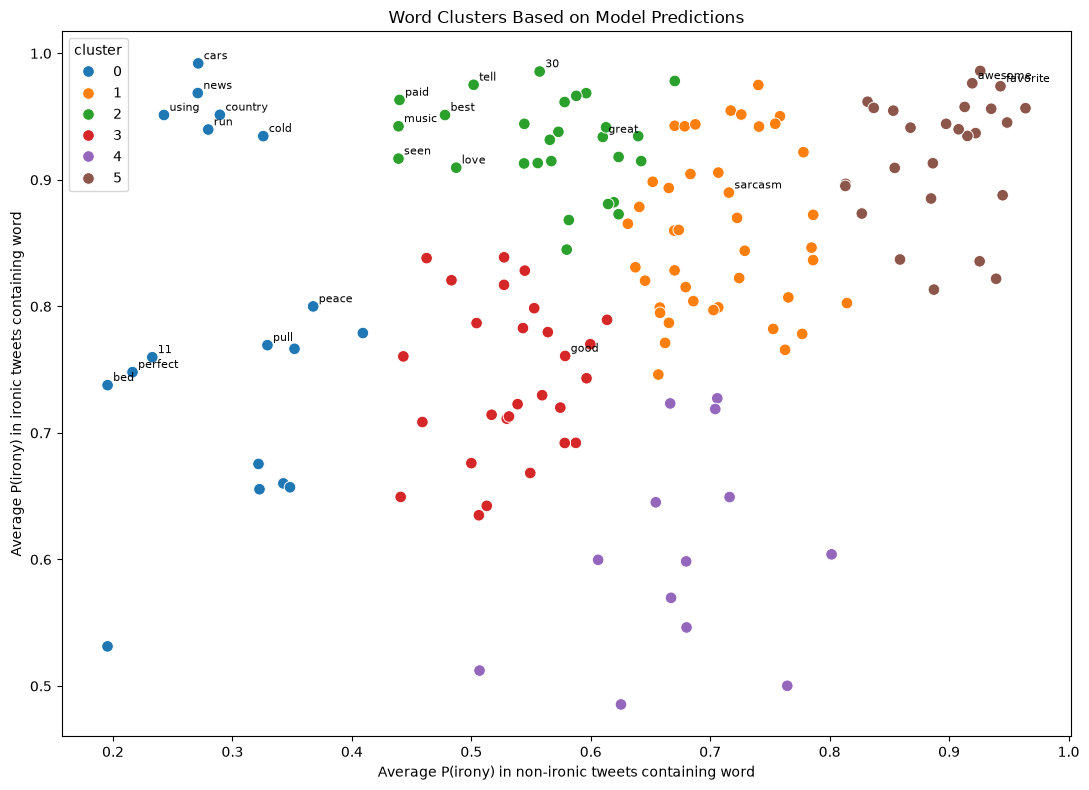

In [14]:
features = word_df[["ironic_score", "non_ironic_score"]]
N_CLUSTERS = 6  # Keep six clusters to match the existing analysis.
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
word_df["cluster"] = kmeans.fit_predict(features)

# Optional quality check. These diagnostics do not automatically select k.
k_candidates = range(2, min(9, len(word_df)))
silhouettes = {
    k: silhouette_score(features, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(features))
    for k in k_candidates
}
print("Silhouette scores by k:", {k: round(v, 3) for k, v in silhouettes.items()})

for cluster, group in word_df.groupby("cluster"):
    print(f"Cluster {cluster} (n={len(group)}):")
    print(", ".join(group["word"].tolist()))
    print()

plt.figure(figsize=(11, 8))
sns.scatterplot(
    data=word_df,
    x="non_ironic_score", y="ironic_score", hue="cluster",
    palette="tab10", s=70
)

# Label selected diagnostic points rather than every word (prevents overlaps).
labels_to_show = set(
    word_df.assign(separation=(word_df["ironic_score"] - word_df["non_ironic_score"]).abs())
    .nlargest(18, "separation")["word"]
)
labels_to_show.update({"great", "good", "perfect", "awesome", "love", "favorite", "sarcasm"})
for row in word_df.itertuples(index=False):
    if row.word in labels_to_show:
        plt.annotate(row.word, (row.non_ironic_score, row.ironic_score),
                     fontsize=8, xytext=(4, 3), textcoords="offset points")

plt.xlabel("Average P(irony) in non-ironic tweets containing word")
plt.ylabel("Average P(irony) in ironic tweets containing word")
plt.title("Word Clusters Based on Model Predictions")
plt.tight_layout()
plt.show()

### Interpretation of the word clusters

The model groups words by **similar average prediction patterns** in ironic and non-ironic tweets. This does not demonstrate that words are close together in the model's internal embedding space. Compare words with a large difference between the two axes to words with high scores in both. In particular, compare positive words such as *perfect*, *great*, *good* and *awesome*: similar sentiment does not necessarily imply similar model behavior.

Sample sizes (`n_ironic`, `n_non_ironic`) are important because rare words may have unstable averages. Cluster numbers/colors are arbitrary and can change if the data or features are changed.

## 5. Compare predicted irony probability to observed irony frequency

The **prediction gap** compares the average predicted P(irony) in tweets containing a word with the proportion of those tweets that are actually labeled ironic. Large gaps identify candidate words for deeper inspection; they do not prove that those words cause the model's errors.

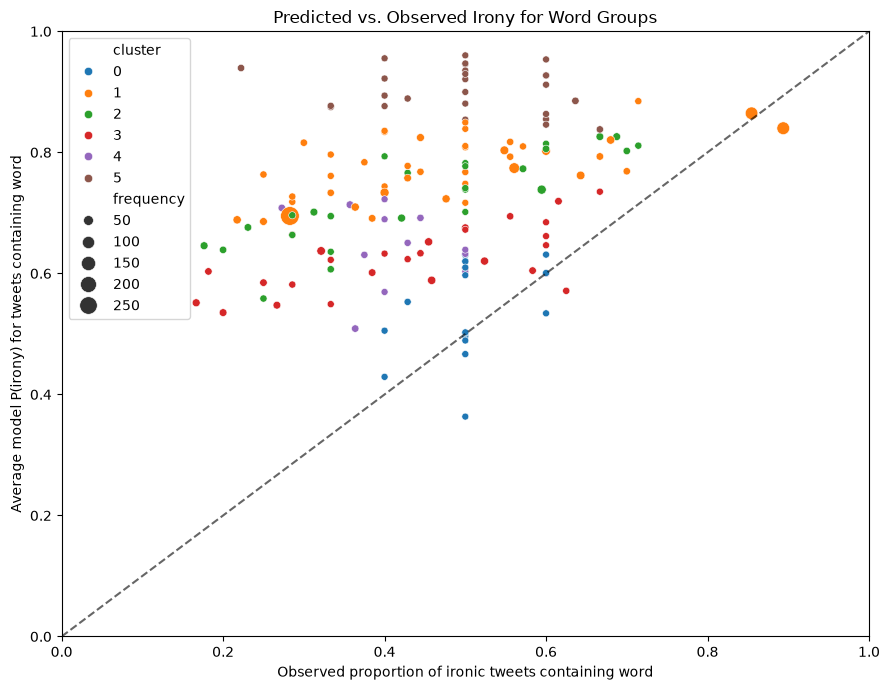

Words with highest positive prediction gap:


,word,frequency,n_ironic,n_non_ironic,actual_irony_share,mean_predicted_irony,prediction_gap
120,things,9,2,7,0.222222,0.939406,0.717183
33,favorite,5,2,3,0.400000,0.955411,0.555411
35,feeling,6,2,4,0.333333,0.876901,0.543568
14,better,9,3,6,0.333333,0.875084,0.541751
31,exactly,5,2,3,0.400000,0.922039,0.522039
42,getting,10,3,7,0.300000,0.815979,0.515979
91,person,8,2,6,0.250000,0.763432,0.513432
86,ones,5,2,3,0.400000,0.893828,0.493828
32,fact,5,2,3,0.400000,0.876464,0.476464
66,lol,23,5,18,0.217391,0.688514,0.471122


In [17]:
plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=word_df,
    x="actual_irony_share", y="mean_predicted_irony",
    hue="cluster", palette="tab10", size="frequency", sizes=(25, 180)
)
plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Equal observed and predicted")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Observed proportion of ironic tweets containing word")
plt.ylabel("Average model P(irony) for tweets containing word")
plt.title("Predicted vs. Observed Irony for Word Groups")
plt.tight_layout()
plt.show()

print("Words with highest positive prediction gap:")
display(word_df.nlargest(15, "prediction_gap")[[
    "word", "frequency", "n_ironic", "n_non_ironic",
    "actual_irony_share", "mean_predicted_irony", "prediction_gap"
]])

word_df.to_csv("irony_word_clusters.csv", sep=";", index=False, encoding="utf-8-sig")

## 6. Controlled substitutions in real tweets

Select up to 25 **true positives** (TP) and 25 **false positives** (FP) that contain characteristic words. Replace exactly one occurrence of a chosen word, review the edited text, and compare P(irony) with the original tweet. Because substitutions can change meaning, this is an exploratory perturbation experiment, not a causal proof of internal word reliance.

In [19]:
# Priority is explicit; if multiple candidate words are present, the first
# word in this list is selected. Change the order if desired.
replacements = [
    ("irony", "comment"), ("sarcasm", "comment"),
    ("great", "okay"), ("love", "like"), ("yay", "well"),
    ("lol", "well"), ("just", "simply"), ("good", "okay"),
    ("awesome", "okay"), ("things", "items"),
    ("wonder", "think"), ("right", "correct"),
    ("talking", "speaking"), ("person", "individual"),
    ("game", "match"), ("happy", "fine")
]


def replace_one_word(text):
    for target, replacement in replacements:
        match = re.search(r"(?<!\w)" + re.escape(target) + r"(?!\w)", text, re.I)
        if match is None:
            continue
        old = match.group()
        new = (replacement.upper() if old.isupper() else
               replacement.capitalize() if old[0].isupper() else replacement)
        return target, text[:match.start()] + new + text[match.end():]
    return None, None


pool = df.loc[df["p_irony"] >= 0.5, ["text", "irony", "p_irony"]].copy()
pool["group"] = np.where(pool["irony"] == 1, "TP", "FP")
edits = pool["text"].apply(replace_one_word)
pool["word"] = edits.map(lambda item: item[0])
pool["edited_text"] = edits.map(lambda item: item[1])
pool = pool.dropna(subset=["word", "edited_text"])

selected_rows = []
for group in ["TP", "FP"]:
    candidates = pool[pool["group"] == group].sample(frac=1, random_state=42)
    used = Counter()
    chosen = []
    for idx, row in candidates.iterrows():
        if len(chosen) < 25 and used[row["word"]] < 5:
            chosen.append(idx)
            used[row["word"]] += 1
    for idx in candidates.index:
        if len(chosen) >= 25:
            break
        if idx not in chosen:
            chosen.append(idx)
    selected_rows.extend(chosen)

pairs = pool.loc[selected_rows].rename(columns={
    "text": "original_text", "p_irony": "p_before"
}).reset_index(drop=True)

print("Selected pairs per outcome:")
print(pairs["group"].value_counts())
display(pairs[["group", "word", "original_text", "edited_text"]])
pairs.to_csv("irony_word_pairs_for_review.csv", sep=";", index=False, encoding="utf-8-sig")

Selected pairs per outcome:
group
TP    25
FP    25
Name: count, dtype: int64


,group,word,original_text,edited_text
0,TP,sarcasm,How dare Charles Barkley have an intelligent c...,How dare Charles Barkley have an intelligent c...
1,TP,sarcasm,I love getting up at 4 30 so I can wait on oth...,I love getting up at 4 30 so I can wait on oth...
2,TP,just,So Jeremy Irons and Alan Rickman are BOTH in M...,So Jeremy Irons and Alan Rickman are BOTH in M...
3,TP,sarcasm,@user @user the cop also had prior misconduct ...,@user @user the cop also had prior misconduct ...
4,TP,sarcasm,Just got yelled at by proxy. It's going to be ...,Just got yelled at by proxy. It's going to be ...
5,TP,great,Literally functioning on 4 hours of sleep and ...,Literally functioning on 4 hours of sleep and ...
6,TP,irony,@user I actually think he needs to use the you...,@user I actually think he needs to use the you...
7,TP,irony,The song was 'don't cry for me Argentina' #irony,The song was 'don't cry for me Argentina' #com...
8,TP,sarcasm,@user great story about the student trying to ...,@user great story about the student trying to ...
9,TP,irony,She talkin bout gender roles and we're the nar...,She talkin bout gender roles and we're the nar...


In [20]:
if pairs.empty:
    raise ValueError("No candidate tweets. Expand the replacement list.")

# Review `pairs` first. Delete or edit invalid substitutions before running.
pairs["p_after"] = predict_irony(pairs["edited_text"])
pairs["delta_p_irony"] = pairs["p_after"] - pairs["p_before"]
pairs["prediction_flipped"] = (
    (pairs["p_after"] >= 0.5) != (pairs["p_before"] >= 0.5)
)
summary = pairs.groupby("group").agg(
    n=("delta_p_irony", "size"),
    mean_change=("delta_p_irony", "mean"),
    median_change=("delta_p_irony", "median"),
    flipped=("prediction_flipped", "sum")
)
display(summary)
display(pairs.loc[pairs["delta_p_irony"].abs().nlargest(12).index, [
    "group", "word", "original_text", "edited_text", "p_before", "p_after", "delta_p_irony"
]])
pairs.to_csv("irony_word_substitution_results.csv", sep=";", index=False, encoding="utf-8-sig")

,n,mean_change,median_change,flipped
group,,,,
FP,25,-0.034448,-0.016254,2
TP,25,-0.095857,-0.033130,3


,group,word,original_text,edited_text,p_before,p_after,delta_p_irony
10,TP,yay,Been at the ER now since 10... #yay #not,Been at the ER now since 10... #well #not,0.754056,0.212320,-0.541736
20,TP,love,Love the fact that I turned off my alarm this ...,Like the fact that I turned off my alarm this ...,0.950346,0.573602,-0.376744
14,TP,love,Love waking up to no heat in my apartment #not...,Like waking up to no heat in my apartment #not...,0.929431,0.572801,-0.356630
42,FP,irony,"'I like the hope Jan Ellis writes with, the pr...","'I like the hope Jan Ellis writes with, the pr...",0.716680,0.483069,-0.233611
48,FP,just,I JUST WANT TO BE DONE WITH FINALS #4hoursleft,I SIMPLY WANT TO BE DONE WITH FINALS #4hoursleft,0.536368,0.324175,-0.212194
18,TP,love,I just love being ignored😊|#not😒,I just like being ignored😊|#not😒,0.598382,0.386582,-0.211801
6,TP,irony,@user I actually think he needs to use the you...,@user I actually think he needs to use the you...,0.703673,0.510195,-0.193479
24,TP,right,@user @user @user @user @user we get it right ...,@user @user @user @user @user we get it correc...,0.892704,0.707732,-0.184972
26,FP,sarcasm,@user @user @user We Agree #NHSENGLAND needs t...,@user @user @user We Agree #NHSENGLAND needs t...,0.687566,0.519670,-0.167896
32,FP,lol,@user u do really need to get a wee bit more lol,@user u do really need to get a wee bit more w...,0.689395,0.843050,0.153654


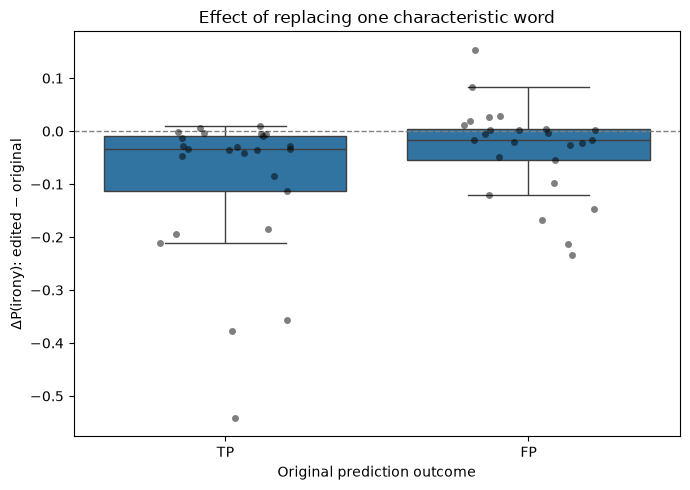

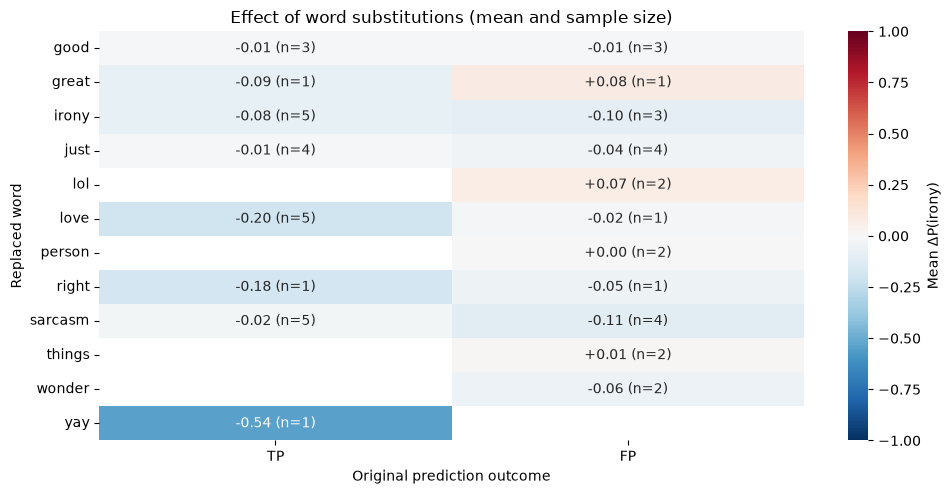

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=pairs, x="group", y="delta_p_irony",
            order=["TP", "FP"], showfliers=False, ax=ax)
sns.stripplot(data=pairs, x="group", y="delta_p_irony",
              order=["TP", "FP"], color="black", alpha=0.5, jitter=0.22, ax=ax)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Original prediction outcome", ylabel="ΔP(irony): edited − original",
       title="Effect of replacing one characteristic word")
plt.tight_layout()
plt.show()

means = pairs.pivot_table(index="word", columns="group", values="delta_p_irony", aggfunc="mean")
counts = pairs.pivot_table(index="word", columns="group", values="delta_p_irony", aggfunc="count")
means = means.reindex(columns=["TP", "FP"])
counts = counts.reindex(columns=["TP", "FP"]).fillna(0).astype(int)
annotations = means.copy().astype(object)
for word in means.index:
    for group in means.columns:
        val = means.loc[word, group]
        annotations.loc[word, group] = (
            f"{val:+.2f} (n={counts.loc[word, group]})" if pd.notna(val) else ""
        )

plt.figure(figsize=(10, max(5, 0.42 * len(means))))
sns.heatmap(means, annot=annotations, fmt="", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, cbar_kws={"label": "Mean ΔP(irony)"})
plt.xlabel("Original prediction outcome")
plt.ylabel("Replaced word")
plt.title("Effect of word substitutions (mean and sample size)")
plt.tight_layout()
plt.show()

## 7. Same six words in ironic and non-ironic contexts

Use **one master set of sentence pairs** for all comparisons. The model evaluates each version once. For each sentence we construct: **Original**, **Without word**, and **Without punctuation**. The context label is assigned by design, not independently verified. Removing an expression can also change intended irony, and removal of an initial expression necessarily removes its separator comma.

In [23]:
# (target word, intended context, original, version without target expression)
test_data = [
    ("Great", "Ironic", "Great, my flight got cancelled again!", "My flight got cancelled again!"),
    ("Great", "Non-ironic", "Great, my flight arrived early!", "My flight arrived early!"),
    ("Perfect", "Ironic", "Perfect, my car broke down on the way to work!", "My car broke down on the way to work!"),
    ("Perfect", "Non-ironic", "Perfect, my car is finally repaired!", "My car is finally repaired!"),
    ("Love", "Ironic", "Love waiting three hours for a delayed train!", "Waiting three hours for a delayed train!"),
    ("Love", "Non-ironic", "Love arriving early on a comfortable train!", "Arriving early on a comfortable train!"),
    ("Awesome", "Ironic", "Awesome, the server crashed right before the deadline!", "The server crashed right before the deadline!"),
    ("Awesome", "Non-ironic", "Awesome, the server finished the backup before the deadline!", "The server finished the backup before the deadline!"),
    ("Thanks", "Ironic", "Thanks, you lost my luggage!", "You lost my luggage!"),
    ("Thanks", "Non-ironic", "Thanks, you found my luggage!", "You found my luggage!"),
    ("Wonderful", "Ironic", "Wonderful, the printer broke right before my presentation!", "The printer broke right before my presentation!"),
    ("Wonderful", "Non-ironic", "Wonderful, the printer worked for my presentation!", "The printer worked for my presentation!")
]

rows = []
for word, context, original, without_word in test_data:
    for version, sentence in {
        "Original": original,
        "Without word": without_word,
        "Without punctuation": original.rstrip("!")
    }.items():
        rows.append({
            "word": word, "context": context,
            "version": version, "text": sentence
        })

test_df = pd.DataFrame(rows)
assert not test_df.duplicated(["word", "context", "version"]).any()
test_df["p_irony"] = predict_irony(test_df["text"], batch_size=12)
test_df["prediction"] = np.where(test_df["p_irony"] >= 0.5, "Irony", "Non-irony")
display(test_df)

test_df.to_csv("irony_linguistic_cues.csv", sep=";", index=False, encoding="utf-8-sig")

,word,context,version,text,p_irony,prediction
0,Great,Ironic,Original,"Great, my flight got cancelled again!",0.932075,Irony
1,Great,Ironic,Without word,My flight got cancelled again!,0.608821,Irony
2,Great,Ironic,Without punctuation,"Great, my flight got cancelled again",0.942996,Irony
3,Great,Non-ironic,Original,"Great, my flight arrived early!",0.972343,Irony
4,Great,Non-ironic,Without word,My flight arrived early!,0.778513,Irony
5,Great,Non-ironic,Without punctuation,"Great, my flight arrived early",0.980669,Irony
6,Perfect,Ironic,Original,"Perfect, my car broke down on the way to work!",0.694017,Irony
7,Perfect,Ironic,Without word,My car broke down on the way to work!,0.487743,Non-irony
8,Perfect,Ironic,Without punctuation,"Perfect, my car broke down on the way to work",0.696729,Irony
9,Perfect,Non-ironic,Original,"Perfect, my car is finally repaired!",0.899633,Irony


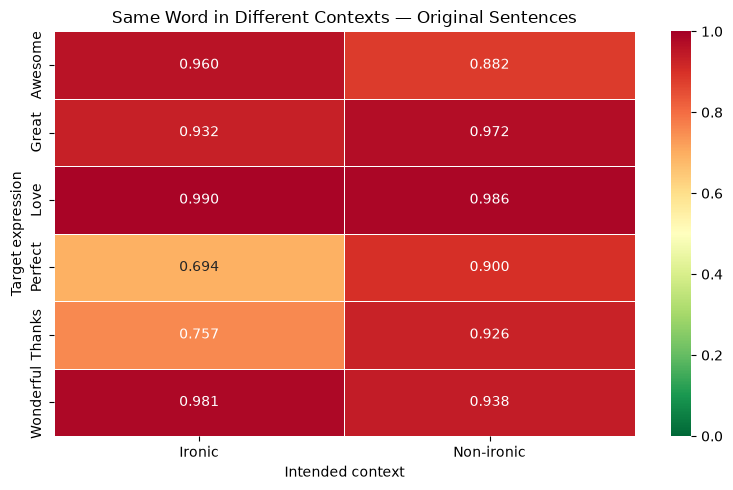

context,Ironic,Non-ironic,delta_context
word,,,
Awesome,0.959716,0.882174,0.077542
Wonderful,0.980977,0.938418,0.042559
Love,0.989846,0.985664,0.004182
Great,0.932075,0.972343,-0.040268
Thanks,0.757139,0.926175,-0.169037
Perfect,0.694017,0.899633,-0.205616


In [24]:
# Ironic vs non-ironic context, keeping the six target expressions.
context_heatmap = test_df.loc[test_df["version"] == "Original"].pivot(
    index="word", columns="context", values="p_irony"
)[["Ironic", "Non-ironic"]]

plt.figure(figsize=(8, 5))
sns.heatmap(context_heatmap, annot=True, fmt=".3f", cmap="RdYlGn_r",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("Same Word in Different Contexts — Original Sentences")
plt.xlabel("Intended context")
plt.ylabel("Target expression")
plt.tight_layout()
plt.show()

context_difference = context_heatmap.assign(
    delta_context=lambda d: d["Ironic"] - d["Non-ironic"]
)
display(context_difference.sort_values("delta_context", ascending=False))

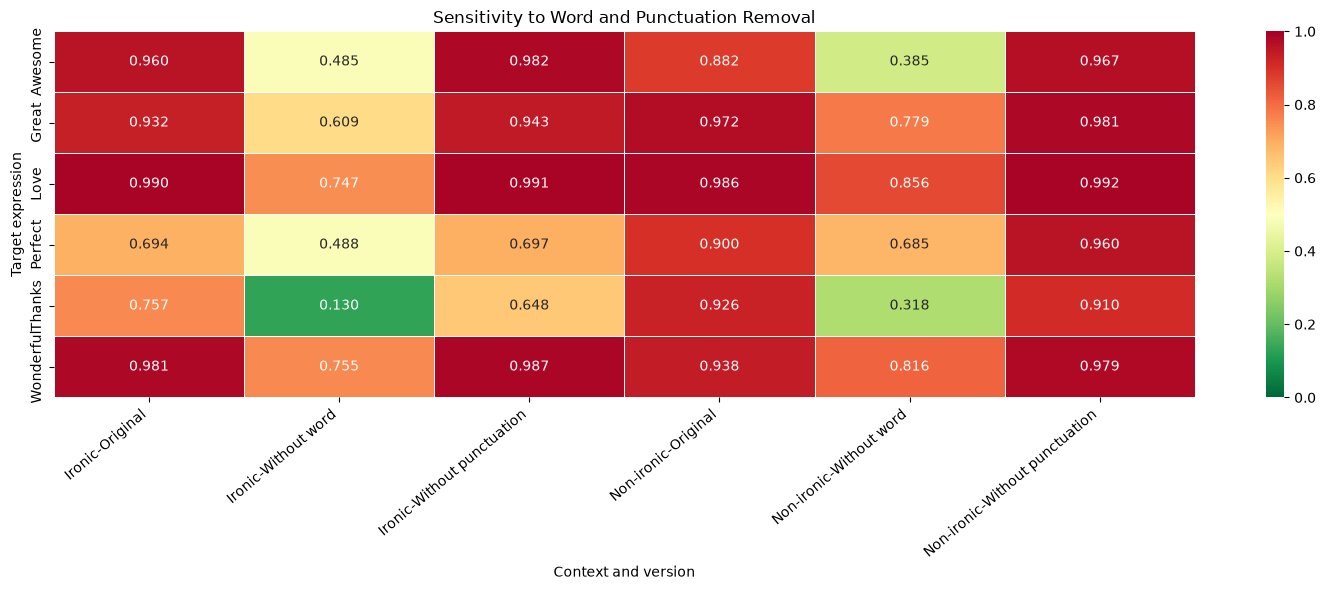

version               Original  Without punctuation  Without word  delta_word  \
word      context                                                               
Awesome   Ironic      0.959716             0.982124      0.484581   -0.475135   
          Non-ironic  0.882174             0.966850      0.384543   -0.497632   
Great     Ironic      0.932075             0.942996      0.608821   -0.323254   
          Non-ironic  0.972343             0.980669      0.778513   -0.193830   
Love      Ironic      0.989846             0.990807      0.747318   -0.242528   
          Non-ironic  0.985664             0.991776      0.855512   -0.130152   
Perfect   Ironic      0.694017             0.696729      0.487743   -0.206274   
          Non-ironic  0.899633             0.959513      0.685210   -0.214423   
Thanks    Ironic      0.757139             0.648049      0.129958   -0.627180   
          Non-ironic  0.926175             0.909926      0.318178   -0.607997   
Wonderful Ironic      0.980977             0.987211      0.755326   -0.225652   
          Non-ironic  0.938418             0.979096      0.815871   -0.122547   

version               delta_punctuation  
word      context                        
Awesome   Ironic               0.022408  
          Non-ironic           0.084676  
Great     Ironic               0.010922  
          Non-ironic           0.008326  
Love      Ironic               0.000961  
          Non-ironic           0.006112  
Perfect   Ironic               0.002712  
          Non-ironic           0.059880  
Thanks    Ironic              -0.109090  
          Non-ironic          -0.016249  
Wonderful Ironic               0.006234  
          Non-ironic           0.040678

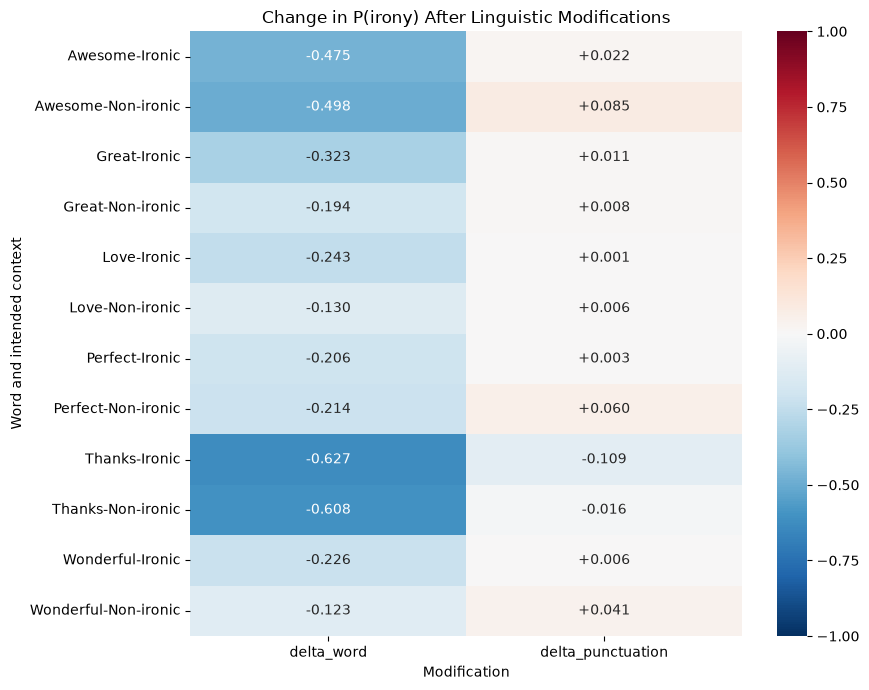

In [25]:
# All versions in one heatmap (no duplicate pivot keys).
version_heatmap = test_df.pivot(
    index="word", columns=["context", "version"], values="p_irony"
)
plt.figure(figsize=(15, 6))
sns.heatmap(version_heatmap, annot=True, fmt=".3f", cmap="RdYlGn_r",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("Sensitivity to Word and Punctuation Removal")
plt.xlabel("Context and version")
plt.ylabel("Target expression")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

comparison = test_df.pivot(
    index=["word", "context"], columns="version", values="p_irony"
)
comparison["delta_word"] = comparison["Without word"] - comparison["Original"]
comparison["delta_punctuation"] = (
    comparison["Without punctuation"] - comparison["Original"]
)
display(comparison)

plt.figure(figsize=(9, 7))
sns.heatmap(comparison[["delta_word", "delta_punctuation"]], annot=True,
            fmt="+.3f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Change in P(irony) After Linguistic Modifications")
plt.xlabel("Modification")
plt.ylabel("Word and intended context")
plt.tight_layout()
plt.show()

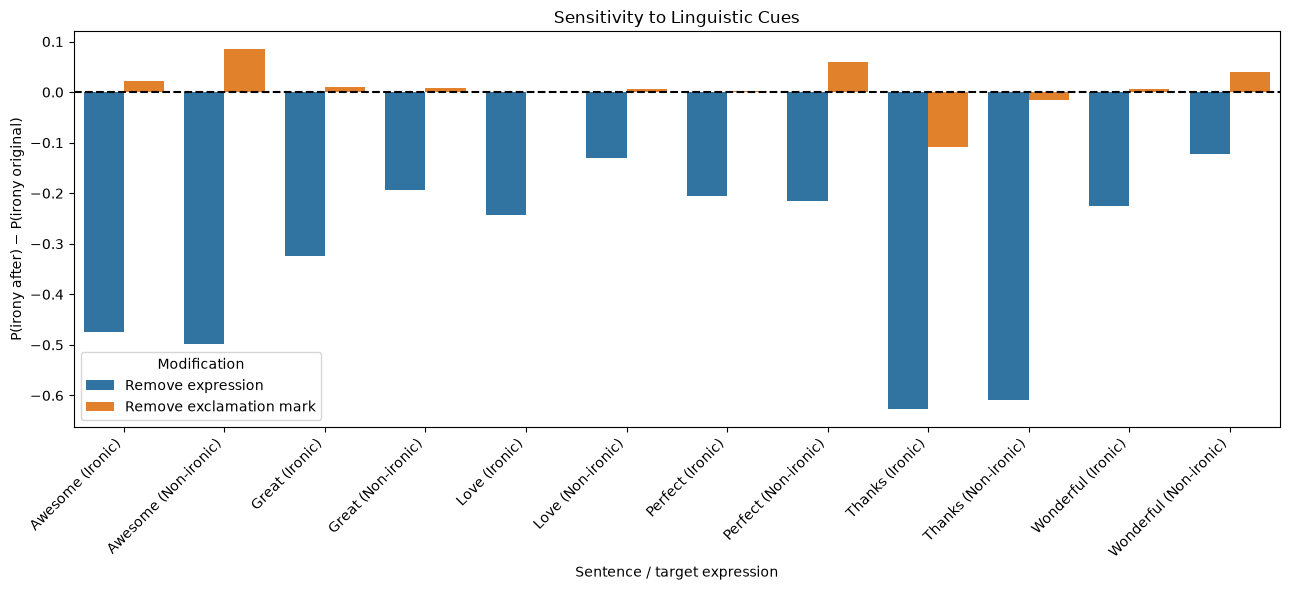

Mean absolute probability change by modification:


version
delta_word           0.322217
delta_punctuation    0.030687
Name: Mean |ΔP|, dtype: float64

In [26]:
# Grouped bars: a direct comparison of sensitivity to the two cue types.
plot_df = comparison[["delta_word", "delta_punctuation"]].reset_index().melt(
    id_vars=["word", "context"], var_name="Modification", value_name="Delta P(irony)"
)
plot_df["Sentence"] = plot_df["word"] + " (" + plot_df["context"] + ")"
plot_df["Modification"] = plot_df["Modification"].map({
    "delta_word": "Remove expression",
    "delta_punctuation": "Remove exclamation mark"
})

plt.figure(figsize=(13, 6))
sns.barplot(data=plot_df, x="Sentence", y="Delta P(irony)",
            hue="Modification", errorbar=None)
plt.axhline(0, color="black", linestyle="--")
plt.title("Sensitivity to Linguistic Cues")
plt.xlabel("Sentence / target expression")
plt.ylabel("P(irony after) − P(irony original)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Mean absolute probability change by modification:")
display(comparison[["delta_word", "delta_punctuation"]].abs().mean().rename("Mean |ΔP|"))

## 8. Interpretation and limitations

- **Word clusters** describe statistical associations between word occurrence and tweet-level model predictions, not internal word representations.
- **Prediction gaps** reveal where a word's associated predicted irony probability exceeds or falls below the observed share of truly ironic tweets; class imbalance and sample size must be considered.
- **Word substitutions** measure sensitivity to edits in real tweets. The selected candidate tweets already had high predicted irony, and some replacements change meaning.
- **Controlled sentences** help compare targeted language modifications, but the examples are few and synthetic. Removing an opening expression may also remove a comma and the ironic meaning itself.

For stronger claims, inspect individual examples and test more sentences while changing only one component at a time.